In [4]:
#Very first step is to import these modules and libraries into the satprocessing kernel
import numpy as np
import dask as ds
import earthaccess as ea
import xarray as xr
import sys
import matplotlib.pyplot as plt
import requests
import pandas as pd
import PyCO2SYS as pyco2
import cartopy
from shapely.ops import unary_union
import cartopy.feature as cfeature
from datetime import date
from scipy.spatial import KDTree
from datasets import Dataset
print("module import success")

import sys
sys.path.append(r'C:\\Users\\edmund.gable\\Documents\\Hollings_2026\\RESOURCES\\python\\utilities\\bootstrap\\')
print("path import success")

import pprint
from environment import bootstrap_environment  
pprint.pprint(bootstrap_environment(preferred="edmund_gable"))
print("success")

from utilities.bootstrap.environment import bootstrap_environment
env = bootstrap_environment(preferred="edmund.gable")
env
print("utilities import success")

#Before this next step, install the library 'resource': conda install -c conda-forge resource
from utilities import get_dates, get_source_file_dates, find_text
find_text("stats")

from utilities import get_prod_files 
get_prod_files("DO", period="DOY")
#"DOY" is climatological 'day of year
#'W' is climatological weekly files

from pathlib import Path

root = Path(r"C:\Users\edmund.gable\Documents\Hollings_2026\GitHub\MOM6-COBALT_2026")
raw_data = Path(r"C:\Users\edmund.gable\Documents\Hollings_2026\GitHub\MOM6-COBALT_2026\data\Raw_Data")
model_data = Path(r"Z:\\MOM6\Hindcasts\\BTM-O2-REGRID")
processed_data=Path(r"C:\Users\edmund.gable\Documents\Hollings_2026\GitHub\MOM6-COBALT_2026\data\Processed_Data\comparison")




c:\Users\edmund.gable\.conda\envs\satprocessing\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


module import success
path import success
⚠ Unrecognized preferred label 'edmund_gable'. Valid options: ['NECMAC04363461.local', 'nefscsatdata', 'guihyde', 'Mac.localdomain', 'gdavis', 'egable']
{'dataset_path': WindowsPath('C:/Users/edmund.gable/Documents/Hollings_2026/DATASETS'),
 'hostname': 'NECL04363598',
 'lookuptable_path': WindowsPath('C:/Users/edmund.gable/Documents/Hollings_2026/RESOURCES/workflow_resources/lookuptables'),
 'metadata_path': WindowsPath('C:/Users/edmund.gable/Documents/Hollings_2026/RESOURCES/workflow_resources/metadata'),
 'project_root': WindowsPath('C:/Users/edmund.gable/Documents/Hollings_2026/RESOURCES/python'),
 'python_path': WindowsPath('C:/Users/edmund.gable/Documents/Hollings_2026/RESOURCES/python'),
 'satlogs_path': WindowsPath('C:/Users/edmund.gable/Documents/Hollings_2026/RESOURCES/logs/satprocessing'),
 'timestamp': datetime.datetime(2026, 6, 16, 16, 7, 8, 974920),
 'utilities_path': WindowsPath('C:/Users/edmund.gable/Documents/Hollings_2026/RESO

<frozen importlib._bootstrap>:488: RuntimeWarning: numpy.ndarray size changed, may indicate binary incompatibility. Expected 16 from C header, got 96 from PyObject


⚠ Unrecognized preferred label 'edmund.gable'. Valid options: ['NECMAC04363461.local', 'nefscsatdata', 'guihyde', 'Mac.localdomain', 'gdavis', 'egable']
utilities import success
regex for string stats is: re.compile('stats', re.IGNORECASE)
📦 Found 365 .nc files in: C:\Users\edmund.gable\Documents\Hollings_2026\DATASETS\MOM6\V0.0\PRODUCTS\NES_9KM_CLIMATOLOGY\DO


In [ ]:
#!pip install datasets

  Using cached datasets-5.0.0-py3-none-any.whl.metadata (23 kB)
  Using cached filelock-3.29.3-py3-none-any.whl.metadata (2.0 kB)
  Using cached dill-0.4.1-py3-none-any.whl.metadata (10 kB)
  Using cached httpx-0.28.1-py3-none-any.whl.metadata (7.1 kB)
  Using cached xxhash-3.7.0-cp313-cp313-win_amd64.whl.metadata (13 kB)
  Using cached multiprocess-0.70.19-py313-none-any.whl.metadata (7.5 kB)
  Using cached huggingface_hub-1.19.0-py3-none-any.whl.metadata (14 kB)
  Using cached anyio-4.13.0-py3-none-any.whl.metadata (4.5 kB)
  Using cached httpcore-1.0.9-py3-none-any.whl.metadata (21 kB)
  Using cached h11-0.16.0-py3-none-any.whl.metadata (8.3 kB)
  Using cached click-8.4.1-py3-none-any.whl.metadata (2.6 kB)
  Using cached hf_xet-1.5.1-cp37-abi3-win_amd64.whl.metadata (4.9 kB)
  Using cached typer-0.25.1-py3-none-any.whl.metadata (15 kB)
  Using cached shellingham-1.5.4-py2.py3-none-any.whl.metadata (3.5 kB)
  Using cached rich-15.0.0-py3-none-any.whl.metadata (18 kB)
  Using cached a

In [5]:
#create the MOM6-COBALT grid df
df_mom6_raw=pd.read_csv(r"C:\Users\edmund.gable\Documents\Hollings_2026\GitHub\MOM6-COBALT_2026\data\Raw_Data\MOM6_COBALT\2004_01_01.csv")
grid_extent = df_mom6_raw[["lat", "lon"]].drop_duplicates().reset_index(drop=True)

# 3. Create a unique integer ID for every single unique grid cell
grid_extent["grid_id"] = grid_extent.index + 1  # 1-indexed IDs

# 4. Save this file so you don't have to keep rebuilding it
export_path=(r"C:\\Users\\edmund.gable\\Documents\\Hollings_2026\\GitHub\\MOM6-COBALT_2026\\data\\Index\\MOM6_Grid_Extent.csv")
#grid_extent.to_csv(export_path, date_format='%Y-%m-%d %H:%M:%S', index=False)


print(f"Grid extent file created with {len(grid_extent)} unique grid IDs.")
print(grid_extent.head())

dsg=grid_extent.set_index(['lat','lon']).to_xarray()
dsg

Grid extent file created with 159005 unique grid IDs.
         lat        lon  grid_id
0  22.525518 -82.468483        1
1  22.525518 -82.387807        2
2  22.525518 -82.307132        3
3  22.525518 -82.226456        4
4  22.525518 -82.145780        5


<xarray.Dataset> Size: 1MB
Dimensions:  (lat: 413, lon: 385)
Coordinates:
  * lat      (lat) float64 3kB 22.53 22.59 22.65 22.71 ... 48.25 48.31 48.37
  * lon      (lon) float64 3kB -82.47 -82.39 -82.31 ... -51.65 -51.57 -51.49
Data variables:
    grid_id  (lat, lon) int64 1MB 1 2 3 4 5 ... 159002 159003 159004 159005

Text(0.5, 1.0, 'MOM6 Bottom Dissolved Oxygen\n2004-01-01 12:00:00')

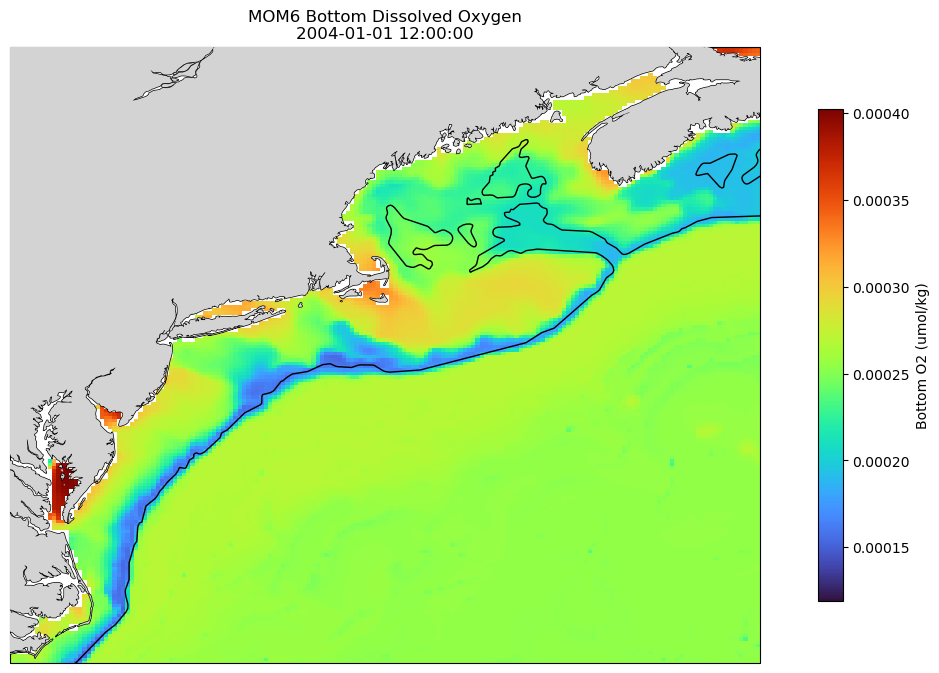

In [6]:
#To plot a full gridded map of MOM6 outputs:
ds=xr.open_dataset(r"Z:\MOM6\Hindcasts\BTM-O2-REGRID\2004\01\CEFI-BTM_O2-HINDCAST-20040101.nc")

bathym = cfeature.NaturalEarthFeature(name='bathymetry_K_200', scale='10m', category='physical')
bathym = unary_union(list(bathym.geometries()))

fig = plt.figure(figsize=(15, 8)) #set figure size
map_projection = cartopy.crs.PlateCarree() #set map projection
ax = plt.axes(projection=map_projection) #link projection to axes
im = plt.pcolormesh(ds.lon,ds.lat,ds.btm_o2[0],cmap='turbo') #what to plot
cb=plt.colorbar(im,shrink=0.8,label='Bottom O2 (umol/kg)') #how big+what to label color bar
ax.add_feature(cartopy.feature.COASTLINE, linewidth=1) #add coastlines
ax.add_feature(cartopy.feature.LAND, zorder=100, facecolor='lightgrey') #add land mask 
ax.add_geometries(bathym, facecolor='none', edgecolor='black', crs=cartopy.crs.PlateCarree()) #add bathymetry line
ax.set_extent([-77, -63, 34.5, 46])
ax.set_title(f'MOM6 Bottom Dissolved Oxygen\n{pd.to_datetime(ds.time[0].values)}')

In [34]:
#define these functions 
def classify_DO(df, DO_column, battery_col=None):
  clean_df=df[df[DO_column]>0].copy()
  classified_df = clean_df.copy()

  classified_df.loc[classified_df[DO_column] >= 3.9, 'DO_status'] = 'Low Oxygen'
  classified_df.loc[classified_df[DO_column] > 5.0, 'DO_status'] = 'Oxygenated' 
  classified_df.loc[classified_df[DO_column] < 3.9, 'DO_status'] = 'Mildly Hypoxic'
  classified_df.loc[classified_df[DO_column] < 2.41, 'DO_status'] = 'Hypoxia'
  classified_df.loc[classified_df[DO_column] < 0.2, 'DO_status'] = 'Anoxia'
    
  return classified_df
  
def open_file(file):
  ds=xr.open_dataset(file)
  df=ds.to_dataframe()
  print(df.columns.to_list())
  return df

def check_units(ds, DO_col):
  print(ds[DO_col].attrs)  

In [8]:
#Use this function to match observational coordinates to MOM6 coordinates 
def prepare_df(df, DO_col, id_col, obs_depth_col, bottom_depth_col, lat_col, lon_col, time_col, mom6_grid_df, battery_col=None):
  
  # drop values that are nan
  df=df.dropna(subset=[DO_col])


  # make sure measurement is at bottom
  depth_mismatch = abs(df[obs_depth_col] - df[bottom_depth_col])
  depth_mismatch=depth_mismatch.astype(float)

  max_mismatch=np.minimum(0.1*df[bottom_depth_col], 20)
  df_filtered=df[depth_mismatch<max_mismatch].copy()

  # match to MOM6 grid timestamp
  df_filtered["matched_time"] = pd.to_datetime(df_filtered[time_col]).dt.normalize() + pd.Timedelta(hours=12)
 
  # match to spatial grids
  pt_lats = xr.DataArray(df_filtered[lat_col], dims='points')
  pt_lons = xr.DataArray(df_filtered[lon_col], dims='points')

  # Query the existing dataset directly for the nearest coordinates
  nearest_grid = dsg.sel(lat=pt_lats, lon=pt_lons, method='nearest')

  # Assign those exact grid coordinates back to the dataframe
  #df_filtered['grid_lat'] = nearest_grid.lat.values
  #df_filtered['grid_lon'] = nearest_grid.lon.values
  df_filtered['matched_lat'] = nearest_grid.lat.values
  df_filtered['matched_lon'] = nearest_grid.lon.values
  df_filtered['grid_id'] = nearest_grid.grid_id.values
  df=df_filtered

  rename_dict = {
        DO_col: "dissolved_oxygen",
        id_col: "id",
        obs_depth_col: "obs_depth",
        bottom_depth_col: "bottom_depth",
        lat_col: "lat",
        lon_col: "lon",
        time_col: "time",
    }
  df = df.rename(columns=rename_dict)
  #take everything in one grid cell of point data and average it
  agg_rules = {
        "dissolved_oxygen": "mean",    # Average the oxygen measurements in the cell
        "obs_depth": "mean",           # Average the depths they were taken at
        "bottom_depth": "mean",        # Average the seafloor depths
        "lat": "mean",                 # Average the exact vessel latitudes
        "lon": "mean",                 # Average the exact vessel longitudes
        "id": "first",                 # Keep the cruise/vessel ID 
        #"time": "first",               # DON'T Keep the original raw timestamp
        "matched_lat": "first",        # Grid lats are identical for this group, keep first
        "matched_lon": "first"         # Grid lons are identical for this group, keep first
    }
    
#Group by the day and grid cell, apply rules, and restore flat dataframe structure
  df = df.groupby(['matched_time', 'grid_id']).agg(agg_rules).reset_index()
  df=classify_DO(df, DO_col, battery_col=battery_col)
  requested_columns = [
        "id",
        "lat",
        "lon",
        "obs_depth",
        "bottom_depth",
        "dissolved_oxygen",
        "DO_status",  
        "grid_id",
        "matched_time",
        "matched_lat",
        "matched_lon"
        ]

 
  return df[requested_columns]

In [44]:
#1. Open the observational data file 
file=(r"C:\Users\edmund.gable\Documents\Hollings_2026\GitHub\MOM6-COBALT_2026\data\Raw_Data\Hydrographic_Monitoring\errdap_search.nc")
df=open_file(file)

#check to make sure units are in mg/L 
check_units(df, 'dissolved_oxygen')
df=df[df['cruise_id']!='HB2101'] #removed this cruise because the oxygen detector malfunctioned

#2. read in the grid extent
mom6_grid_df=pd.read_csv(r"C:\Users\edmund.gable\Documents\Hollings_2026\GitHub\MOM6-COBALT_2026\data\Index\MOM6_Grid_Extent.csv")

#3. prepare and export the prepared dataset
dfp=prepare_df(df, 'dissolved_oxygen', 'cruise_id', 'depth', 'bottom_depth', 'latitude', 'longitude', 'UTC_DATETIME', mom6_grid_df)
dfp
#dfp.to_csv(processed_data / "Hydrographic_Monitoring_matched_2009_2025.csv")

['UTC_DATETIME', 'latitude', 'longitude', 'depth', 'dissolved_oxygen', 'cruise_id', 'purpose_code', 'bottom_depth', 'GEAR_TYPE']
{}


,id,lat,lon,obs_depth,bottom_depth,dissolved_oxygen,DO_status,grid_id,matched_time,matched_lat,matched_lon
0,DEL0909,39.974998,-72.511703,61.500000,67.0,7.100000,Oxygenated,107154,2009-08-18 12:00:00,39.966708,-72.545378
1,DEL0909,40.058300,-72.838303,49.099998,52.0,6.025000,Oxygenated,107535,2009-08-18 12:00:00,40.029446,-72.868081
2,DEL0909,40.070000,-72.826698,50.099998,55.0,6.100000,Oxygenated,107921,2009-08-18 12:00:00,40.092184,-72.787405
3,DEL0909,40.098301,-71.758301,76.400002,82.0,6.100000,Oxygenated,107934,2009-08-18 12:00:00,40.092184,-71.738622
4,DEL0909,39.013302,-73.816704,33.700001,37.0,6.200000,Oxygenated,101363,2009-08-19 12:00:00,39.025637,-73.836189
...,...,...,...,...,...,...,...,...,...,...,...
5346,HB2506,42.349998,-66.818298,312.500000,323.0,6.500000,Oxygenated,121855,2025-12-06 12:00:00,42.350756,-66.817408
5347,HB2506,40.826698,-66.936699,89.500000,96.0,7.583333,Oxygenated,112614,2025-12-07 12:00:00,40.845041,-66.898083
5348,HB2506,41.349998,-66.510002,84.500000,91.0,8.783334,Oxygenated,115699,2025-12-07 12:00:00,41.346946,-66.494705
5349,HB2506,40.543301,-67.724998,128.500000,136.0,6.758333,Oxygenated,110679,2025-12-08 12:00:00,40.531351,-67.704840


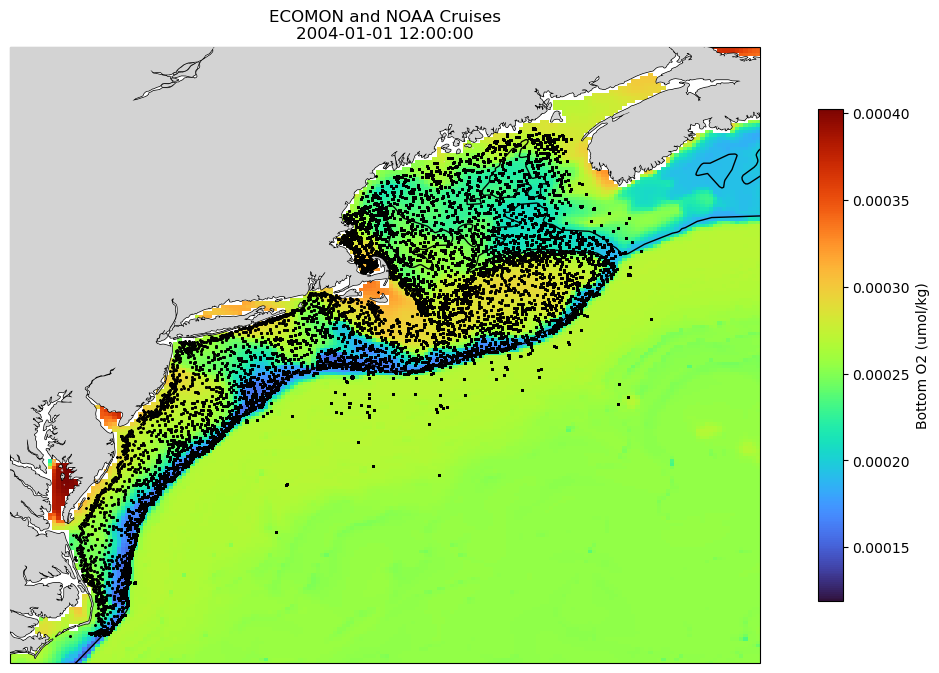

In [31]:
bathym = cfeature.NaturalEarthFeature(name='bathymetry_K_200', scale='10m', category='physical')
bathym = unary_union(list(bathym.geometries()))

fig = plt.figure(figsize=(15, 8)) #set figure size
map_projection = cartopy.crs.PlateCarree() #set map projection
ax = plt.axes(projection=map_projection) #link projection to axes
im = plt.pcolormesh(ds.lon,ds.lat,ds.btm_o2[0],cmap='turbo') #what to plot
cb=plt.colorbar(im,shrink=0.8,label='Bottom O2 (umol/kg)') #how big+what to label color bar
ax.add_feature(cartopy.feature.COASTLINE, linewidth=1) #add coastlines
ax.add_feature(cartopy.feature.LAND, zorder=100, facecolor='lightgrey') #add land mask 
ax.add_geometries(bathym, facecolor='none', edgecolor='black', crs=cartopy.crs.PlateCarree()) #add bathymetry line
ax.set_extent([-77, -63, 34.5, 46])
ax.set_title(f'ECOMON and NOAA Cruises\n{pd.to_datetime(ds.time[0].values)}')
plt.scatter(df.longitude.astype(float), df.latitude.astype(float), c='black', s=0.1)

In [45]:
#Use this function to match mom6 data to observational data 
def load_matching_mom6_data(df, model_data):

    #load in a dataframe list to fill
    df_list = []

    # Get the list of unique datetimes from observational data
    unique_dates = pd.to_datetime(df['matched_time']).dt.normalize().unique()

    print(f"Found {len(unique_dates)} unique dates to query")

    #set the date structure
    for date in unique_dates:
        year = str(date.year)
        month = f"{date.month:02d}"
        day = f"{date.day:02d}"
        
        # Match the exact filename structure
        file_name = f"CEFI-BTM_O2-HINDCAST-{year}{month}{day}.nc"
        target_file_path = model_data / year / month / file_name
        
        # Filter the cruise dataframe down to just the points needed for this specific day
        current_date_str = f"{year}-{month}-{day}"
        df_day = df[pd.to_datetime(df['matched_time']).dt.normalize() == date]
        
        # Check if the file exists before attempting to open it
        if target_file_path.exists():
            print(f"Extracting data for {current_date_str}...")
            
            # Open the dataset
            ds = xr.open_dataset(target_file_path)
            
            # Extract ONLY the bottom oxygen variable
            o2_slice = ds['btm_o2'] 
            
            #  Target only the specific grid IDs present on this day ---
            for _, row in df_day.iterrows():
              try:
                    # Use coordinate matching (.sel) instead of positional indexing (.isel)
                    # This searches the grid using the target latitude and longitude directly
                    model_val = o2_slice.sel(
                        lat=row['matched_lat'], 
                        lon=row['matched_lon'], 
                        method='nearest'
                    ).values
                    
                    #  convert the resulting numpy array/scalar into a standard float
                    btm_o2_val = float(np.atleast_1d(model_val)[0])
              except Exception as e:
                    print(f" Lookup failed for Lat {row['matched_lat']}, Lon {row['matched_lon']}: {e}")
                    btm_o2_val = np.nan

                
                # Build a single clean row combining the cruise data with the model value
              matched_row = row.to_dict()
              matched_row['btm_o2'] = btm_o2_val
              df_list.append(matched_row)
            
            # Close the dataset file connection 
            ds.close()
        else:
            print(f"⚠️ Model file not found for {year}-{month}-{day} at: {target_file_path}")
            # If the file is missing, still retain the cruise data rows but fill model data with NaN
            for _, row in df_day.iterrows():
                matched_row = row.to_dict()
                matched_row['btm_o2'] = np.nan
                df_list.append(matched_row)

    # 4. Convert all individual rows into one single, master DataFrame
    if df_list:
        final_model_df = pd.DataFrame(df_list)
        return final_model_df
    else:
        print("No matching model files were found or loaded.")
        return pd.DataFrame() # Return empty dataframe as fallback

In [11]:
ds=xr.open_dataset(r"Z:\MOM6\Hindcasts\BTM-O2-REGRID\2004\01\CEFI-BTM_O2-HINDCAST-20040101.nc")
df=ds.to_dataframe()
df=df.reset_index()
print(df.columns.to_list())


['time', 'lat', 'lon', 'btm_o2']


In [46]:
df=pd.read_csv(processed_data / "Hydrographic_Monitoring_matched_2009_2025.csv")
loaded_datasets= load_matching_mom6_data(df, model_data)


Found 1232 unique dates to query
Extracting data for 2009-08-18...
Extracting data for 2009-08-19...
Extracting data for 2009-08-20...
Extracting data for 2009-08-21...
Extracting data for 2009-08-22...
Extracting data for 2009-08-23...
Extracting data for 2009-08-24...
Extracting data for 2009-08-25...
Extracting data for 2009-08-26...
Extracting data for 2009-08-27...
Extracting data for 2009-08-28...
Extracting data for 2009-11-03...
Extracting data for 2009-11-04...
Extracting data for 2009-11-05...
Extracting data for 2009-11-07...
Extracting data for 2009-11-08...
Extracting data for 2009-11-09...
Extracting data for 2009-11-10...
Extracting data for 2009-11-11...
Extracting data for 2009-11-17...
Extracting data for 2009-11-18...
Extracting data for 2009-11-19...
Extracting data for 2010-02-03...
Extracting data for 2010-02-04...
Extracting data for 2010-02-09...
Extracting data for 2010-02-10...
Extracting data for 2010-02-12...
Extracting data for 2010-02-13...
Extracting data

In [47]:
#keep this code block separate to avoid accidentally runnning long function again
loaded_datasets.to_csv(processed_data / "ECOMON_MOM6_comparison.csv")

In [4]:
ds=xr.open_dataset(r"Z:\MOM6\Hindcasts\BTM-O2-REGRID\2001\01\CEFI-BTM_O2-HINDCAST-20010101.nc")
ds

<xarray.Dataset> Size: 642kB
Dimensions:  (time: 1, lat: 413, lon: 385)
Coordinates:
  * time     (time) datetime64[ns] 8B 2001-01-01T12:00:00
  * lat      (lat) float64 3kB 22.53 22.59 22.65 22.71 ... 48.25 48.31 48.37
  * lon      (lon) float64 3kB -82.47 -82.39 -82.31 ... -51.65 -51.57 -51.49
Data variables:
    btm_o2   (time, lat, lon) float32 636kB ...
Attributes: (12/34)
    NumFilesInSet:          1
    title:                  NWA12_COBALT_2025_04_bugfixes
    associated_files:       areacello: 19930101.ocean_static.nc
    grid_type:              regular
    grid_tile:              N/A
    external_variables:     areacello
    ...                     ...
    Conventions:            CF-1.0
    History:                Translated to CF-1.0 Conventions by Netcdf-Java C...
    geospatial_lat_min:     22.494149096919973
    geospatial_lat_max:     48.40498164398673
    geospatial_lon_min:     -82.50882070524109
    geospatial_lon_max:     -51.448697088915196

In [41]:
#Function to convert model o2 to mg/L and calculate the difference between the model and the observed
def delta_difference(df):
    df=df.dropna(subset=['btm_o2'])
    df['bottom_o2_mgL']=df['btm_o2']*31998*1.025
    df['delta_difference']=df['bottom_o2_mgL']-df['dissolved_oxygen']
    print(f'mean of delta difference between observational data and model data is {df['delta_difference'].mean}')
    return df


In [48]:
output=delta_difference(loaded_datasets)
output.to_csv(processed_data / "ECOMON_MOM6_comparison.csv")
output

mean of delta difference between observational data and model data is <bound method Series.mean of 0       2.077795
1       3.294636
2       3.067808
3       0.009071
4       3.469272
          ...   
3967    0.330041
3968    2.807588
3969    2.484043
3970    0.192071
3971    1.002149
Name: delta_difference, Length: 3963, dtype: float64>


,Unnamed: 0,id,lat,lon,obs_depth,bottom_depth,dissolved_oxygen,DO_status,grid_id,matched_time,matched_lat,matched_lon,btm_o2,bottom_o2_mgL,delta_difference
0,0,DEL0909,39.9750,-72.5117,61.5,67.0,7.100000,Oxygenated,107154,2009-08-18 12:00:00,39.966708,-72.545378,0.000280,9.177795,2.077795
1,1,DEL0909,40.0583,-72.8383,49.1,52.0,6.025000,Oxygenated,107535,2009-08-18 12:00:00,40.029446,-72.868081,0.000284,9.319636,3.294636
2,2,DEL0909,40.0700,-72.8267,50.1,55.0,6.100000,Oxygenated,107921,2009-08-18 12:00:00,40.092184,-72.787405,0.000280,9.167808,3.067808
3,3,DEL0909,40.0983,-71.7583,76.4,82.0,6.100000,Oxygenated,107934,2009-08-18 12:00:00,40.092184,-71.738622,0.000186,6.109071,0.009071
4,4,DEL0909,39.0133,-73.8167,33.7,37.0,6.200000,Oxygenated,101363,2009-08-19 12:00:00,39.025637,-73.836189,0.000295,9.669272,3.469272
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
3967,3967,PC2305,40.9367,-70.8983,48.0,53.0,7.500000,Oxygenated,112949,2023-11-14 12:00:00,40.907779,-70.931866,0.000239,7.830041,0.330041
3968,3968,HB2304,41.9983,-69.1817,183.0,194.0,4.664706,Low Oxygen,119516,2023-11-14 12:00:00,41.974327,-69.157001,0.000228,7.472294,2.807588
3969,3969,HB2304,41.8217,-69.3150,176.0,188.0,4.930769,Low Oxygen,118744,2023-11-15 12:00:00,41.848851,-69.318353,0.000226,7.414812,2.484043
3970,3970,HB2304,41.0600,-69.2250,52.0,56.0,7.900000,Oxygenated,113740,2023-11-16 12:00:00,41.033256,-69.237677,0.000247,8.092071,0.192071


In [1]:
import matplotlib.colors as mcolors
bathym = cfeature.NaturalEarthFeature(name='bathymetry_K_200', scale='10m', category='physical')
bathym = unary_union(list(bathym.geometries()))

fig = plt.figure(figsize=(15, 8)) #set figure size
map_projection = cartopy.crs.PlateCarree() #set map projection
ax = plt.axes(projection=map_projection) #link projection to axes
sc=ax.scatter(output['matched_lon'].astype(float), output['matched_lat'].astype(float), c=output['delta_difference'], cmap='RdBu_r', s=25, edgecolors='black', linewidths=0.2, transform=cartopy.crs.PlateCarree())

cb = plt.colorbar(sc, shrink=0.8, label='Delta Difference (Observed - Model mg/L)')

# Optional: Center the colorbar around 0 if you want to balance over/underestimation
# import matplotlib.colors as mcolors
# sc.set_norm(mcolors.TwoSlopeNorm(vcenter=0))

# 5. Add map layers and features
ax.add_feature(cfeature.COASTLINE, linewidth=1)
ax.add_feature(cfeature.LAND, zorder=100, facecolor='lightgrey')
ax.add_geometries(bathym, facecolor='none', edgecolor='black', linewidth=0.5, crs=cartopy.crs.PlateCarree())

# 6. Set map spatial limits (Mid-Atlantic Bight / New England shelf)
ax.set_extent([-77, -63, 34.5, 46])

# 7. Add text decoration
ax.set_title('ECOMON and NOAA Cruises\nDelta Difference (Model Bottom $O_2$ - Observed)', fontsize=14)

plt.show()

NameError: name 'cfeature' is not defined

In [42]:
def prepare_df_no_depth(df, DO_col, id_col, lat_col, lon_col, time_col, mom6_grid_df, battery_col=None):
    # 1. Drop values that are nan (explicitly copy to avoid SettingWithCopy warnings)
    df_filtered = df.dropna(subset=[DO_col]).copy()

    # 2. FILTER BATTERY (Only if a battery column name was provided)
    if battery_col is not None:
        df_filtered = df_filtered[df_filtered[battery_col] >= 50]
        
    df_filtered = df_filtered.reset_index(drop=True)
    
    # 3. Match to MOM6 grid timestamp
    df_filtered["matched_time"] = pd.to_datetime(df_filtered[time_col]).dt.normalize() + pd.Timedelta(hours=12)
     
    # 4. Match to spatial grids
    pt_lats = xr.DataArray(df_filtered[lat_col], dims='points')
    pt_lons = xr.DataArray(df_filtered[lon_col], dims='points')

    # Query the existing dataset directly for the nearest coordinates
    # (Note: ensure 'dsg' is defined globally or passed into the function)
    nearest_grid = dsg.sel(lat=pt_lats, lon=pt_lons, method='nearest')

    # Assign those exact grid coordinates back to the dataframe
    df_filtered['matched_lat'] = nearest_grid.lat.values
    df_filtered['matched_lon'] = nearest_grid.lon.values
    df_filtered['grid_id'] = nearest_grid.grid_id.values

    # 5. Rename Columns
    rename_dict = {
        DO_col: "dissolved_oxygen",
        id_col: "id",
        lat_col: "lat",
        lon_col: "lon",
        time_col: "time",
    }
    df_mapped = df_filtered.rename(columns=rename_dict)
    
    # 6. Aggregate data by grid cell and day
    agg_rules = {
        "dissolved_oxygen": "mean",     # Average the oxygen measurements in the cell
        "lat": "mean",                  # Average the exact vessel latitudes
        "lon": "mean",                  # Average the exact vessel longitudes
        "id": "first",                  # Keep the cruise/vessel ID 
        "matched_lat": "first",         # Grid lats are identical for this group
        "matched_lon": "first"          # Grid lons are identical for this group
    }
    
    df_agg = df_mapped.groupby(['matched_time', 'grid_id']).agg(agg_rules).reset_index()
    
    # 7. Classify DO (Pass 'dissolved_oxygen' because columns were renamed)
    df_classified = classify_DO(df_agg, 'dissolved_oxygen', battery_col=battery_col)
    
    # 8. Filter to requested columns
    requested_columns = [
        "id",
        "lat",
        "lon",
        "dissolved_oxygen",
        "DO_status",  
        "grid_id",
        "matched_time",
        "matched_lat",
        "matched_lon"
    ]
    
    return df_classified[requested_columns]

In [23]:
ds=xr.open_dataset(r"C:\Users\edmund.gable\Documents\Hollings_2026\GitHub\MOM6-COBALT_2026\data\Raw_Data\eMOLT\eMOLT_2000_2026.nc")
ds

<xarray.Dataset> Size: 47MB
Dimensions:            (row: 981807)
Dimensions without coordinates: row
Data variables:
    tow_id             (row) float64 8MB ...
    time               (row) datetime64[ns] 8MB ...
    latitude           (row) float32 4MB ...
    longitude          (row) float32 4MB ...
    temperature        (row) float32 4MB ...
    DO                 (row) float32 4MB ...
    DO_percentage      (row) float32 4MB ...
    water_detect_perc  (row) float32 4MB ...
    sensor_type        (row) object 8MB ...
Attributes: (12/30)
    cdm_data_type:             Point
    contact_email:             george.maynard@noaa.gov
    contact_name:              George Maynard
    Conventions:               COARDS, CF-1.6, ACDD-1.3, ISSCFG
    creator_name:              George Maynard
    dataset_status:            OnGoing
    ...                        ...
    subsetVariables:           sensor_type
    summary:                   This is a DO test. DATA NOT FOR USE, QC/QA NOT...
    time_coverage_end:         2026-05-24T23:53:49Z
    time_coverage_start:       2023-07-11T17:32:44Z
    title:                     DO data
    Westernmost_Easting:       -75.0321

In [37]:
file=(r"C:\Users\edmund.gable\Documents\Hollings_2026\GitHub\MOM6-COBALT_2026\data\Raw_Data\eMOLT\eMOLT_2000_2026.nc")
df=open_file(file)
print(df.columns.to_list())

check_units(df, 'DO')

mom6_grid_df=pd.read_csv(r"C:\Users\edmund.gable\Documents\Hollings_2026\GitHub\MOM6-COBALT_2026\data\Index\MOM6_Grid_Extent.csv")

dfp=prepare_df_no_depth(df, 'DO', 'tow_id', 'latitude', 'longitude', 'time', mom6_grid_df, 'water_detect_perc')
#dfp
dfp.to_csv(processed_data / "eMOLT_matched_2023_2026.csv")

['tow_id', 'time', 'latitude', 'longitude', 'temperature', 'DO', 'DO_percentage', 'water_detect_perc', 'sensor_type']
['tow_id', 'time', 'latitude', 'longitude', 'temperature', 'DO', 'DO_percentage', 'water_detect_perc', 'sensor_type']
{}


In [38]:
loaded_datasets=load_matching_mom6_data(dfp, model_data)
loaded_datasets.to_csv(processed_data / "eMOLT_MOM6_matched_data.csv")

Found 692 unique dates to query
Extracting data for 2023-07-31...
Extracting data for 2023-08-01...
Extracting data for 2023-08-02...
Extracting data for 2023-08-03...
Extracting data for 2023-08-04...
Extracting data for 2023-08-05...
Extracting data for 2023-08-06...
Extracting data for 2023-08-07...
Extracting data for 2023-08-08...
Extracting data for 2023-08-09...
Extracting data for 2023-08-10...
Extracting data for 2023-08-11...
Extracting data for 2023-08-12...
Extracting data for 2023-08-13...
Extracting data for 2023-08-14...
Extracting data for 2023-08-15...
Extracting data for 2023-08-16...
Extracting data for 2023-08-17...
Extracting data for 2023-08-18...
Extracting data for 2023-08-19...
Extracting data for 2023-08-20...
Extracting data for 2023-08-21...
Extracting data for 2023-08-22...
Extracting data for 2023-08-23...
Extracting data for 2023-08-24...
Extracting data for 2023-08-25...
Extracting data for 2023-08-26...
Extracting data for 2023-08-27...
Extracting data 

<>:38: SyntaxWarning: invalid escape sequence '\D'
<>:39: SyntaxWarning: invalid escape sequence '\D'
<>:38: SyntaxWarning: invalid escape sequence '\D'
<>:39: SyntaxWarning: invalid escape sequence '\D'
C:\Users\edmund.gable\AppData\Local\Temp\ipykernel_10820\2487653224.py:38: SyntaxWarning: invalid escape sequence '\D'
  f"Mean $\Delta$: {mean_delta:+.2f} mg/L\n"
C:\Users\edmund.gable\AppData\Local\Temp\ipykernel_10820\2487653224.py:39: SyntaxWarning: invalid escape sequence '\D'
  f"Median $\Delta$: {median_delta:+.2f} mg/L\n"


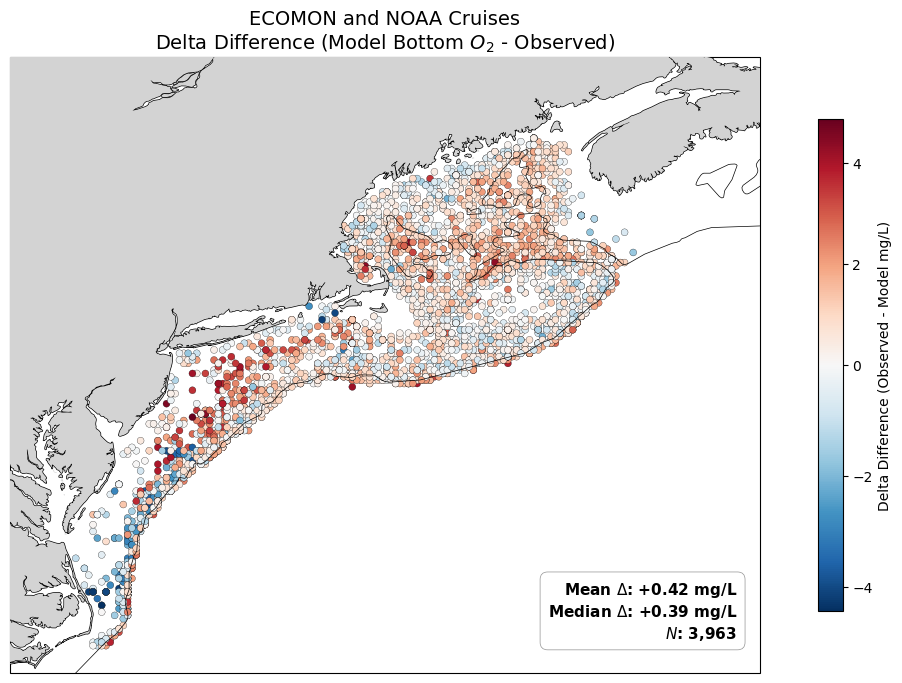

In [8]:
import matplotlib.colors as mcolors

final=pd.read_csv(r"C:\Users\edmund.gable\Documents\Hollings_2026\GitHub\MOM6-COBALT_2026\data\Processed_Data\comparison\ECOMON_MOM6_comparison.csv")

bathym = cfeature.NaturalEarthFeature(name='bathymetry_K_200', scale='10m', category='physical')
bathym = unary_union(list(bathym.geometries()))

fig = plt.figure(figsize=(15, 8)) #set figure size
map_projection = cartopy.crs.PlateCarree() #set map projection
ax = plt.axes(projection=map_projection) #link projection to axes
sc=ax.scatter(final['matched_lon'].astype(float), final['matched_lat'].astype(float), c=final['delta_difference'], cmap='RdBu_r', s=25, edgecolors='black', linewidths=0.2, transform=cartopy.crs.PlateCarree())

cb = plt.colorbar(sc, shrink=0.8, label='Delta Difference (Observed - Model mg/L)')

# Optional: Center the colorbar around 0 if you want to balance over/underestimation
# import matplotlib.colors as mcolors
sc.set_norm(mcolors.TwoSlopeNorm(vcenter=0))

# 5. Add map layers and features
ax.add_feature(cfeature.COASTLINE, linewidth=1)
ax.add_feature(cfeature.LAND, zorder=100, facecolor='lightgrey')
ax.add_geometries(bathym, facecolor='none', edgecolor='black', linewidth=0.5, crs=cartopy.crs.PlateCarree())

# 6. Set map spatial limits (Mid-Atlantic Bight / New England shelf)
ax.set_extent([-77, -63, 34.5, 46])

# 7. Add text decoration
ax.set_title('ECOMON and NOAA Cruises\nDelta Difference (Model Bottom $O_2$ - Observed)', fontsize=14)

#8. Add text to display mean average
# 1. Calculate the stats cleanly (ignoring any stray NaNs)
mean_delta = final['delta_difference'].mean()
median_delta = final['delta_difference'].median()  
total_pts = len(final['delta_difference'].dropna())

# 2. Format the display string (adding the median with dynamic +/- sign formatting)
text_str = (
    f"Mean $\Delta$: {mean_delta:+.2f} mg/L\n"
    f"Median $\Delta$: {median_delta:+.2f} mg/L\n"
    f"$N$: {total_pts:,}"
)

# 3. Define the bounding box style (semi-transparent white block)
box_style = dict(boxstyle='round,pad=0.5', facecolor='white', alpha=0.85, edgecolor='gray', linewidth=0.5)

# 4. Place the text box in the lower-right quadrant of the axes view
ax.text(
    0.97, 0.05,                   # Coordinates (x=97% right, y=5% up from bottom)
    text_str, 
    transform=ax.transAxes,       # Lock placement to screen space
    fontsize=11, 
    fontweight='bold',
    va='bottom', 
    ha='right', 
    bbox=box_style,
    zorder=105                    # Sits cleanly on top of gray landmasses
)
# =====================================================================
plt.show()

In [ ]:
final

In [50]:
ds=xr.open_dataset(r"Z:\MOM6\Hindcasts\BTM-O2-REGRID\2023\07\CEFI-BTM_O2-HINDCAST-20230731.nc")
df=ds.to_dataframe()
df.to_csv(processed_data / "lookatme.csv")

Discontinued Code:

In [ ]:

def load_matching_mom6_data(df, model_data):
    # 1. Change this to a list to hold daily dataframes
    df_list = []

    # Get the list of unique datetimes from observational data
    unique_dates = pd.to_datetime(df['matched_time']).dt.normalize().unique()

    print(f"Found {len(unique_dates)} unique dates to query")

    for date in unique_dates:
        year = str(date.year)
        month = f"{date.month:02d}"
        day = f"{date.day:02d}"
        
        # Match the exact filename structure
        file_name = f"CEFI-BTM_O2-HINDCAST-{year}{month}{day}.nc"
        target_file_path = model_data / year / month / file_name

        # Filter the cruise dataframe down to just the points needed for this specific day
        current_date_str = f"{year}-{month}-{day}"
        df_day = df[pd.to_datetime(df['matched_time']).dt.normalize() == date]
        
        # Check if the file exists before attempting to open it
        if target_file_path.exists():
            print(f"Extracting data for {year}-{month}-{day}...")
            
            # Open the dataset
            ds = xr.open_dataset(target_file_path)
            
            # 2. Extract ONLY the bottom oxygen variable to keep memory footprint low
            # CRITICAL: Replace 'o2_bottom' with the exact name of the variable inside your netCDF file!
            o2_slice = ds['btm_o2'] 
            
            # 3. Convert this specific spatial grid slice into a flat pandas DataFrame
            daily_df = o2_slice.to_dataframe().reset_index()
            
            # Keep only the columns you care about
            # Note: Depending on your NetCDF setup, 'time' might automatically be included
            keep_cols = ['lat', 'lon', 'btm_o2'] 
            daily_df = daily_df[[c for c in daily_df.columns if c in keep_cols or c == 'time']]
            
            # Explicitly track which date this grid belongs to
            daily_df['matched_time'] = pd.to_datetime(f"{year}-{month}-{day}")
            
            # Append this day's table to our master list
            df_list.append(daily_df)
            
            # Close the dataset file connection safely
            ds.close()
        else:
            print(f"⚠️ Warning: Model file not found for {year}-{month}-{day} at: {target_file_path}")
            
    # 4. Concatenate all individual daily dataframes into one single, master DataFrame
    if df_list:
        final_model_df = pd.concat(df_list, ignore_index=True)
        return final_model_df
    else:
        print(" No matching model files were found or loaded.")
        return pd.DataFrame() # Return empty dataframe as fallback

In [ ]:
def prepare_df(df, DO_col, id_col, obs_depth_col, bottom_depth_col, lat_col, lon_col, time_col, mom6_grid_df, battery_col=None):
  #drop values that are nan
  df=df.dropna(subset=[DO_col])
  #classify the oxygen level
  df_working=classify_DO(df, DO_col, battery_col=None)
  #make sure measurement is at bottom
  depth_mismatch = abs(df_working[obs_depth_col] - df_working[bottom_depth_col])
  df_filtered=df_working[depth_mismatch<10].copy()
  #match to MOM6 grid timestamp
  df_filtered["matched_time"] = pd.to_datetime(df_filtered[time_col]).dt.normalize() + pd.Timedelta(hours=12)
 
  #match to spatial grids
  pt_lats = xr.DataArray(df[lat_col], dims='points')
  pt_lons = xr.DataArray(df[lon_col], dims='points')

  # Query your existing dataset directly for the nearest coordinates
  nearest_grid = dsg.sel(lat=pt_lats, lon=pt_lons, method='nearest')

  # Assign those exact grid coordinates back to your dataframe
  df['grid_lat'] = nearest_grid.lat.values
  df['grid_lon'] = nearest_grid.lon.values

  df_filtered['matched_lat']=matched_lat_lon[:, 0]
  df_filtered['matched_lon']=matched_lat_lon[:, 1]
  return df_filtered


In [ ]:

def load_matching_mom6_data(df, model_data):
    loaded_datasets={}

    #get the list of unique datetimes from observational data
    unique_dates=pd.to_datetime(df['matched_time']).dt.normalize().unique()

    print(f"found {len(unique_dates)} unique dates to query")

    for date in unique_dates:
    # 2. Format year, month, and day components
      year = str(date.year)
      month = f"{date.month:02d}"
      day = f"{date.day:02d}"
        
     # 3. Match the exact filename structure: CEFI-BTM_O2-HINDCAST-YYYYMMDD.nc
      file_name = f"CEFI-BTM_O2-HINDCAST-{year}{month}{day}.nc"
        
      # Build the path: Base/Year/Month/Filename
      #         # (Note: Based on your path, there isn't a separate folder for Day, just Year and Month)
      target_file_path = model_data / year / month / file_name
        
      # 4. Check if the file exists before attempting to open it
      if target_file_path.exists():
            print(f"Loading data for {year}-{month}-{day}...")
            # Open the dataset with chunks for memory-efficient lazy loading
            ds = xr.open_dataset(target_file_path, chunks={'time': 1})
            
            # Store it in our dictionary using the date string as the key
            date_key = date.strftime('%Y-%m-%d')
            loaded_datasets[date_key] = ds
      else:
            print(f"⚠️ Warning: Model file not found for {year}-{month}-{day} at: {target_file_path}")
            
    return loaded_datasets


In [ ]:
def prepare_df(df, DO_col, id_col, obs_depth_col, bottom_depth_col, lat_col, lon_col, time_col, mom6_grid_df, battery_col=None):
    # 1. Drop values that are NaN in the target DO column
    df = df.dropna(subset=[DO_col])

    # 2. Classify the oxygen level (Note: changed battery_col=None to battery_col=battery_col to pass it through)
    df_working = classify_DO(df, DO_col, battery_col=battery_col)

    # 3. Make sure measurement is near the bottom (< 10 meters)
    depth_mismatch = abs(df_working[obs_depth_col] - df_working[bottom_depth_col])
    df_filtered = df_working[depth_mismatch < 10].copy()

    # 4. Match to MOM6 grid timestamp (Daily normalized to 12:00:00)
    df_filtered["matched_time"] = pd.to_datetime(df_filtered[time_col]).dt.normalize() + pd.Timedelta(hours=12)

    # 5. Match to spatial grids using KD-Tree
    # We keep the grid_id tied to the lat/lon pairs in the model array
    model_spatial = (mom6_grid_df[["lat", "lon", "grid_id"]].drop_duplicates().copy())
    model_coords = model_spatial[["lat", "lon"]].values

    tree = KDTree(model_coords)
    raw_coords = df_filtered[[lat_col, lon_col]].values
    _, closest_indices = tree.query(raw_coords)

    # 6. Extract matched coordinates and grid IDs
    matched_lat_lon = model_coords[closest_indices]
    df_filtered["matched_lat"] = matched_lat_lon[:, 0]
    df_filtered["matched_lon"] = matched_lat_lon[:, 1]

    # Map the unique grid_id from the corresponding tree positions
    df_filtered["grid_id"] = (model_spatial["grid_id"].iloc[closest_indices].values)

    # 7. Rename the raw columns to your requested standardized names
    rename_dict = {
        DO_col: "dissolved_oxygen",
        id_col: "id",
        obs_depth_col: "obs_depth",
        bottom_depth_col: "bottom_depth",
        lat_col: "lat",
        lon_col: "lon",
        time_col: "time",
    }
    df_filtered = df_filtered.rename(columns=rename_dict)

    # convert the MOM6-COBALT data to mg/L from mol/kg
    dfm["btm_o2"] = dfm["btm_o2"] * 31998 * 1.025

    # 8. Define the final strict list of columns to return
    requested_columns = [
        "id",
        "time",
        "lat",
        "lon",
        "obs_depth",
        "bottom_depth",
        "dissolved_oxygen",
        "DO_status",  # Included this so you don't lose the tags from classify_DO!
        "grid_id",
        "matched_time",
        "matched_lat",
        "matched_lon"
        ]

    # Return the dataframe filtered tightly down to ONLY these columns
    return df_filtered[requested_columns]